## Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load cleaned dataset

In [2]:
df = pd.read_csv("../data/processed/cleaned_customer_churn.csv")

## Check that it loaded correctly

In [3]:
# Display the first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Check the dataset dimensions
df.shape

(7043, 21)

## Analyze the target variable (Churn)

In [5]:
# How many customers stayed and how many left.
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
# Calculate the percentages
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

### Visualize the churn distribution

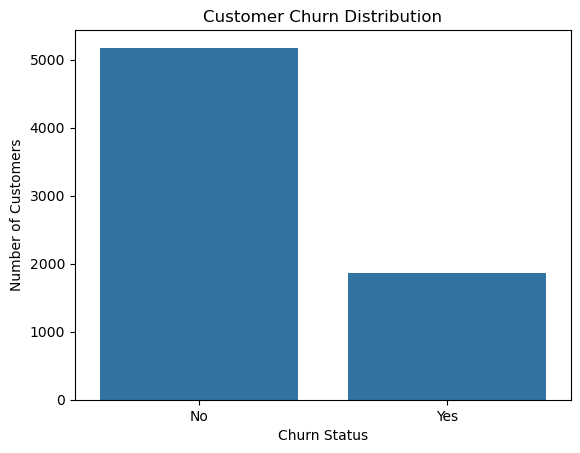

In [7]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

### Target Variable Analysis – Churn Distribution

The dataset contains 7,043 customers, with the following churn distribution:

- **Customers who stayed (No):** 5,174 (73.46%).
- **Customers who churned (Yes):** 1,869 (26.54%).

**Conclusion:** Approximately 26.54% of customers have left the company, indicating a considerable customer retention challenge. The target variable is also imbalanced because the number of customers who stayed is significantly higher than those who churned. This imbalance should be considered during model development and evaluation.

## Analyze customer demographics

In [8]:
# Investigate whether customer characteristics such as gender, senior citizen status, partner status,
# and dependents are associated with churn.
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for column in demographic_columns:
    print(f"\nChurn distribution by {column}")
    print(pd.crosstab(df[column], df["Churn"], normalize="index") * 100)


Churn distribution by gender
Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338

Churn distribution by SeniorCitizen
Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261

Churn distribution by Partner
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903

Churn distribution by Dependents
Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237


### Visualize demographic churn patterns

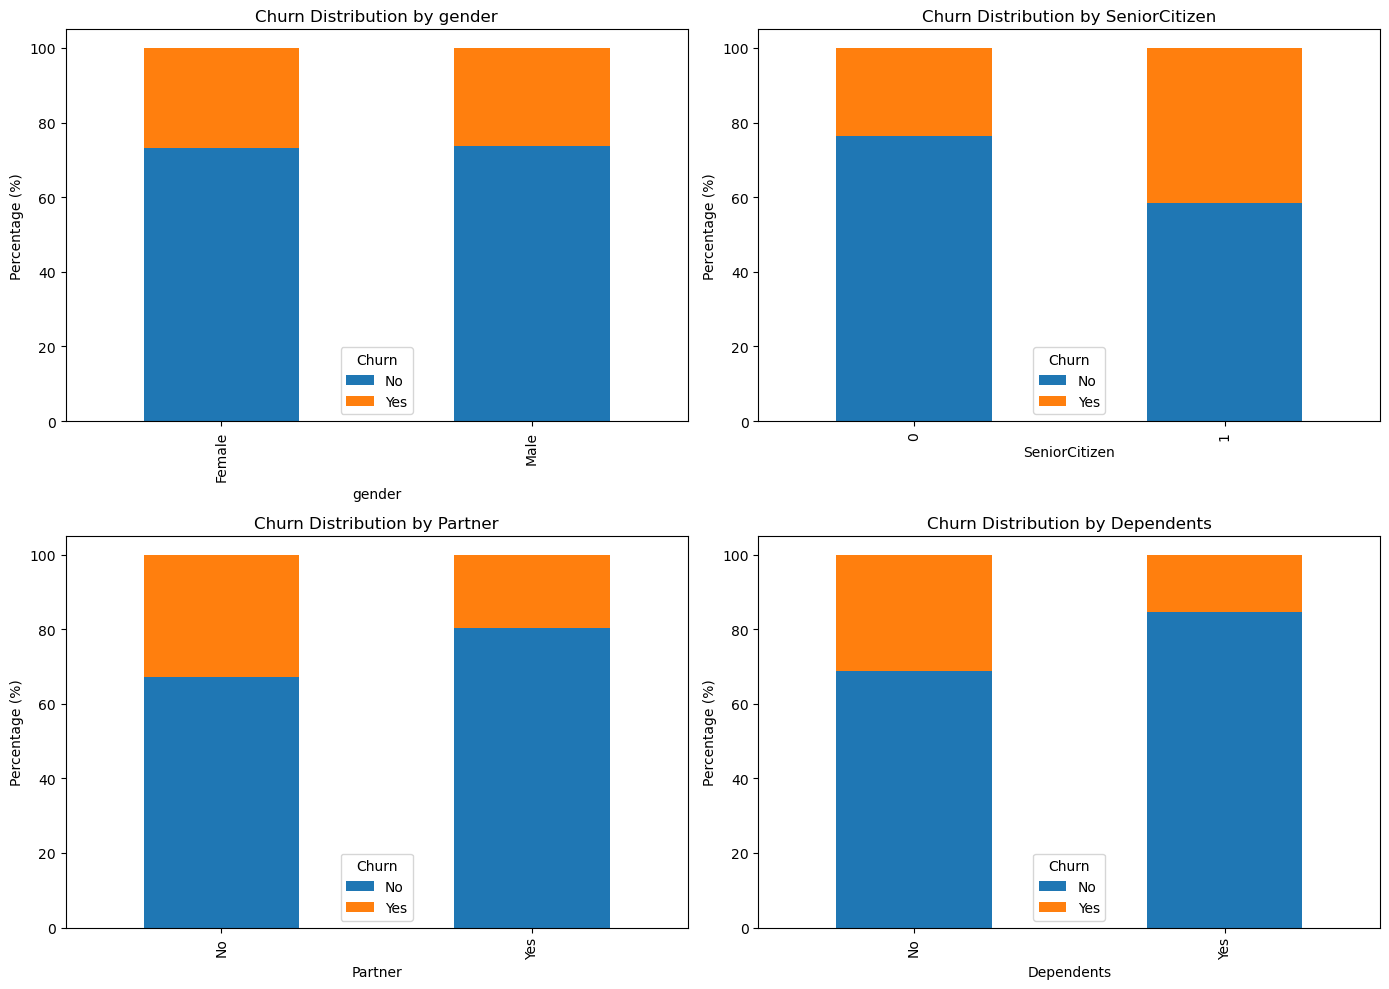

In [9]:
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(demographic_columns, axes.flatten()):
    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_rate.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(f"Churn Distribution by {column}")
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel(column)
    ax.legend(title="Churn")

plt.tight_layout()
plt.show()

### Demographic Analysis – Key Findings

The demographic analysis revealed the following insights:

- **Gender:** Male and female customers have similar churn rates, suggesting that gender has little association with customer churn.
- **Senior Citizen:** Senior citizens have a higher churn rate (41.68%) compared to non-senior citizens (23.61%).
- **Partner:** Customers without partners have a higher churn rate (32.96%) than customers with partners (19.66%).
- **Dependents:** Customers without dependents have a higher churn rate (31.28%) compared to those with dependents (15.45%).

**Conclusion:** Senior citizen, partner, and dependent status show noticeable associations with customer churn, while gender shows very little difference. These insights may help identify customer groups that require targeted retention strategies.

## Descriptive statistics

In [10]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


## Compare numerical features by churn

In [11]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


### Boxplots to visualize the relationship between numerical features and customer churn

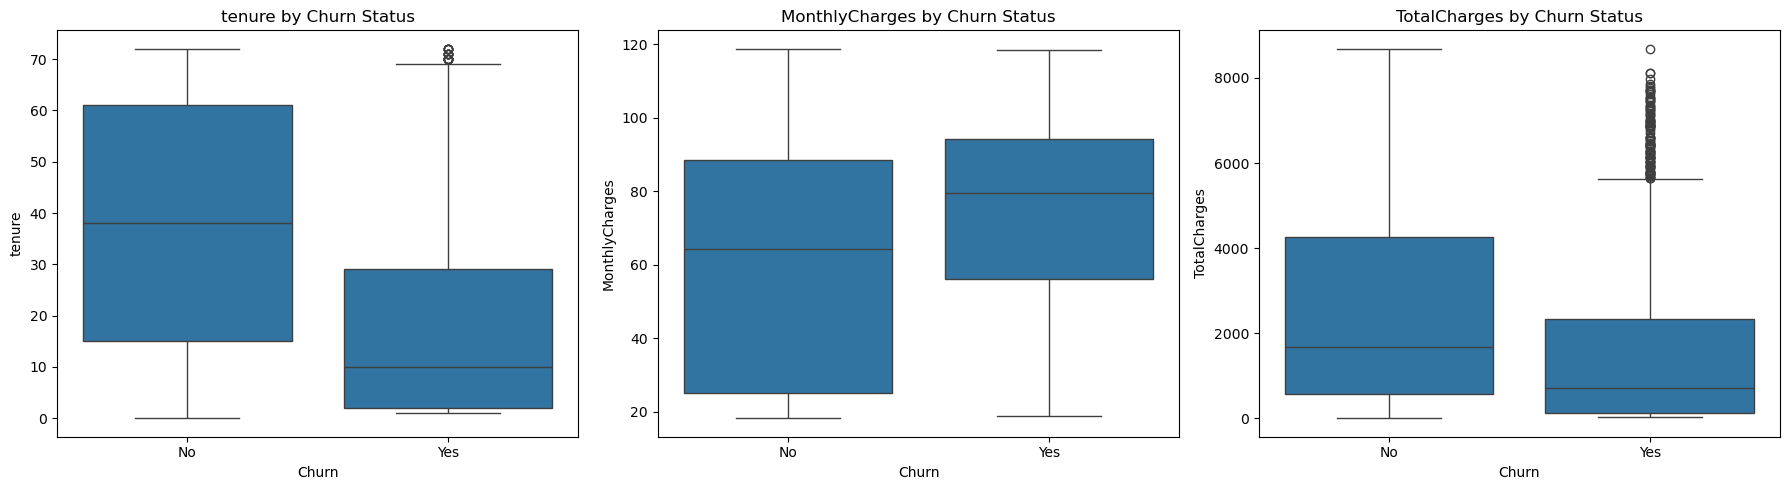

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for column, ax in zip(numerical_columns, axes):
    sns.boxplot(data=df, x="Churn", y=column, ax=ax)
    ax.set_title(f"{column} by Churn Status")

plt.tight_layout()
plt.show()

### Numerical Feature Analysis – Key Findings

The analysis and boxplot visualizations of the numerical features revealed the following insights:

- **Tenure:** Customers who churned had a lower average tenure (17.98 months) compared to those who stayed (37.57 months), indicating that customers with shorter relationships are more likely to leave.
- **Monthly Charges:** Customers who churned paid higher average monthly charges (74.44) than customers who stayed (61.27), suggesting an association between higher monthly charges and churn.
- **Total Charges:** Customers who stayed had higher average total charges (2,549.91) compared to those who churned (1,531.80), likely because they remained customers for longer periods.

**Conclusion:** Tenure and monthly charges appear to be important factors associated with customer churn. Customers with shorter tenure and higher monthly charges tend to have higher churn rates.

## Analyze categorical features against churn

In [13]:
categorical_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "PhoneService",
    "MultipleLines"
]

for column in categorical_columns:
    print(f"\nChurn distribution by {column}")

    print(
        pd.crosstab(
            df[column],
            df["Churn"],
            normalize="index"
        ) * 100
    )


Churn distribution by Contract
Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858

Churn distribution by InternetService
Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980

Churn distribution by PaymentMethod
Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700

Churn distribution by TechSupport
Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.83

### Categorical Feature Analysis – Key Findings

The analysis and visualizations of categorical features revealed the following insights:

- **Contract:** Customers on month-to-month contracts have the highest churn rate (42.71%), while those on two-year contracts have the lowest (2.83%).
- **Internet Service:** Fiber optic customers have a higher churn rate (41.89%) compared to DSL customers (18.96%).
- **Payment Method:** Customers using electronic checks have the highest churn rate (45.29%).
- **Tech Support:** Customers without tech support have a higher churn rate (41.64%) than those with tech support (15.17%).
- **Online Security:** Customers without online security have a higher churn rate (41.77%) compared to those with online security (14.61%).
- **Paperless Billing:** Customers using paperless billing have a higher churn rate (33.57%) than those who do not (16.33%).
- **Phone Service and Multiple Lines:** These features show relatively small differences in churn rates across their categories.

**Conclusion:** Contract type, internet service, payment method, technical support, online security, and paperless billing show noticeable associations with customer churn. In particular, month-to-month contracts and electronic check payments are associated with higher churn rates. These findings may help the company develop more effective customer retention strategies.

## Correlation Analysis
Investigate the relationships between numerical variables to understand how they relate to one another.

In [14]:
# Calculate the correlation matrix
numerical_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

correlation_matrix = numerical_df.corr()

correlation_matrix

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


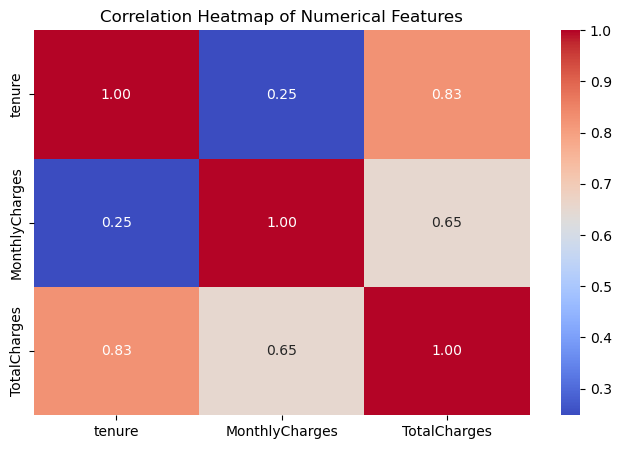

In [15]:
# Visualize the correlation matrix
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Correlation Analysis and Heatmap – Key Findings

The correlation analysis and heatmap were used to examine the relationships among the numerical features of the dataset.

The following relationships were identified:

- **Tenure and TotalCharges (0.826):** Strong positive correlation, indicating that customers who stay longer generally accumulate higher total charges.
- **MonthlyCharges and TotalCharges (0.651):** Moderate positive correlation, suggesting that higher monthly charges are associated with higher accumulated charges.
- **Tenure and MonthlyCharges (0.248):** Weak positive correlation, indicating a relatively weak relationship between the two variables.

**Conclusion:** The heatmap confirms the correlation results, showing that tenure has the strongest positive relationship with TotalCharges, followed by MonthlyCharges and TotalCharges. These findings provide useful insights into customer billing patterns and relationships among numerical features.

## Overall Exploratory Data Analysis (EDA) – Conclusion

The exploratory data analysis revealed several factors associated with customer churn in the telecommunications dataset.

Key findings include:

1. Approximately 26.54% of customers have churned, indicating a customer retention challenge.
2. Senior citizens, customers without partners, and customers without dependents show higher churn rates.
3. Customers with shorter tenure and higher monthly charges are more likely to churn.
4. Month-to-month contract customers have a significantly higher churn rate than customers on longer-term contracts.
5. Customers using electronic checks and fiber optic internet service show higher churn rates.
6. Customers without online security and technical support also show higher churn rates.
7. Correlation analysis revealed a strong positive relationship between tenure and total charges (0.826).

**Overall Conclusion:** The analysis suggests that contract type, tenure, monthly charges, payment method, and additional services are important factors associated with customer churn. These findings will guide the next stage of the project: building a machine learning model to predict customers who are likely to leave the company.